# Fase 6: Modelado de Machine Learning, Evaluación Rigurosa y Detector OOD

**Responsable:** Jorge  
**Proyecto:** Asistente Virtual para Tiendas de Ropa  
**Materia:** Tópicos y Programación Avanzada  

---

## 1. Contexto y Requisitos Metodológicos

El objetivo de esta fase es entrenar, evaluar y comparar modelos de Machine Learning para clasificar texto en lenguaje natural en 13 intenciones (9 de clientes y 4 de administradores) de una tienda de ropa, integrando un mecanismo reproducible de rechazo para consultas fuera de dominio (OOD).

De acuerdo con las directrices del proyecto y el documento oficial (`docs/Proyecto_Integrador.pdf`):
1. **Línea Base Simple:** `DummyClassifier(strategy='most_frequent')` para demostrar que los modelos aportan valor sobre una predicción trivial (clase más frecuente).
2. **Modelos Candidatos:**
   - **Naive Bayes (`ComplementNB`):** Modelo probabilístico clásico para clasificación de texto.
   - **Regresión Logística multinomial:** Modelo lineal regularizado, interpretable y con probabilidades bien calibradas para fijar un umbral de confianza.
3. **Metodología de Evaluación Rigurosa (Sin Data Leakage):**
   - **Selección de modelo e hiperparámetros:** Realizada **exclusivamente mediante validación cruzada estratificada (5 folds)** sobre el conjunto de entrenamiento (`X_train`), optimizando el **F1 Macro** para evitar sesgos.
   - **Conjunto de prueba independiente (`X_test`):** Reservado estrictamente para una **única evaluación final** no sesgada. El conjunto de prueba **nunca se usa para tomar decisiones de modelado**.
4. **Detección Fuera de Dominio (OOD) y Rechazo:** En lugar de asumir un umbral heurístico o afirmar sin respaldo empírico que un umbral de rechazo abierto se calibra por CV en datos cerrados, se implementa una evaluación cuantitativa formal de 5 estrategias de rechazo sobre un conjunto de validación OOD (`data/ood_val.csv`) emparejado con una partición interna de validación en dominio. Se selecciona una estrategia híbrida compuesta (Dual-Gate: Conjunción de probabilidad MSP y cobertura de vocabulario en TF-IDF) que rechaza consultas adversarias fuera de dominio sin penalizar consultas válidas del negocio.
5. **Análisis de Errores Real:** Inspección de ejemplos mal clasificados del conjunto de prueba con etiqueta real, predicción, confianza y justificación técnica.

In [1]:
import os
import sys
from pathlib import Path

# ---------------------------------------------------------------------------
# Configuración robusta de rutas:
# Permite ejecutar el notebook tanto desde 'notebooks/' como desde la raíz
# ---------------------------------------------------------------------------
CURRENT_DIR = Path.cwd().resolve()
if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import yaml
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.models.train import cargar_configuracion, entrenar
from src.models.predict import predecir, cargar_modelo, cargar_detector
from src.data.dataset import cargar_intenciones, dividir

print(f"Directorio de trabajo configurado en: {PROJECT_ROOT}")
print("Módulos importados exitosamente.")

Directorio de trabajo configurado en: C:\Users\usuario\Documents\Proyecto_Topicos\Proyecto_Topicos
Módulos importados exitosamente.


## 2. Inspección de Configuración Central (`src/config.yaml`)

Toda la parametrización del sistema se administra de forma centralizada en `src/config.yaml` para asegurar la reproducibilidad del pipeline y permitir modificaciones en vivo durante la defensa:

In [2]:
config = cargar_configuracion("src/config.yaml")
print("--- Configuración del Modelo y Optimización ---")
print(yaml.dump(config["models"], sort_keys=False))
print("--- Configuración de Detección OOD ---")
print(yaml.dump(config.get("ood", {}), sort_keys=False))
print("--- Configuración de Inferencia en Producción ---")
print(yaml.dump(config["inference"], sort_keys=False))

--- Configuración del Modelo y Optimización ---
scoring: f1_macro
cv_folds: 5
n_jobs: 1
logistic_regression:
  param_grid:
    modelo__C:
    - 0.1
    - 1.0
    - 5.0
    - 10.0
    modelo__class_weight:
    - null
    - balanced
  fixed_params:
    max_iter: 1000
    solver: lbfgs
    random_state: 42
naive_bayes:
  param_grid:
    modelo__alpha:
    - 0.1
    - 0.5
    - 1.0
    - 2.0
  fixed_params: {}

--- Configuración de Detección OOD ---
val_path: data/ood_val.csv
test_path: data/ood_test.csv
estrategia: hybrid_dual_gate
umbral_prob: 0.35
umbral_cobertura: 0.35
umbral_similitud: 0.0

--- Configuración de Inferencia en Producción ---
umbral: 0.35
top_k: 3
usar_detector_ood: true



## 3. Entrenamiento y Selección del Modelo por Validación Cruzada

Ejecutamos el pipeline de entrenamiento reproducible (`entrenar()`).
De acuerdo a la normativa académica del proyecto:
- Se realiza **GridSearchCV con StratifiedKFold (5 particiones)** sobre `X_train`.
- El modelo ganador para producción se selecciona **por mayor F1 Macro en CV**.
- El conjunto de prueba (`X_test`, 20%) se evalúa al final como métrica no sesgada de generalización.
- Se evalúan y calibran cuantitativamente las estrategias de rechazo OOD sobre `data/ood_val.csv`.

In [3]:
pipeline, resultados = entrenar("src/config.yaml")

print(f"\nTotal de muestras del dataset: {resultados['total_muestras']}")
print(f"Muestras de entrenamiento (X_train): {resultados['muestras_train']}")
print(f"Muestras de prueba independiente (X_test): {resultados['muestras_test']}")
print(f"\nCriterio de Selección: {resultados['modelo_produccion']['criterio']}")
print(f"Modelo Ganador: {resultados['modelo_produccion']['nombre']}")
print(f"Mejor F1 Macro en CV (X_train): {resultados['modelo_produccion']['mejor_cv_score']:.4f}")
print(f"F1 Macro en Test (X_test): {resultados['modelo_produccion']['test_f1_macro']:.4f}")
print(f"Accuracy en Test (X_test): {resultados['modelo_produccion']['test_accuracy']:.4f}")

[2026-11-01 10:39:23,446] INFO - Cargando dataset desde: C:\Users\usuario\Documents\Proyecto_Topicos\Proyecto_Topicos\data\raw\intenciones.csv


[2026-11-01 10:39:23,450] INFO - Total de registros: 1040 | Clases únicas: 13


[2026-11-01 10:39:23,485] INFO - Train: 832 ejemplos | Test: 208 ejemplos


[2026-11-01 10:39:23,486] INFO - --- Evaluando Modelo 1: Línea Base (Dummy Most Frequent) ---


[2026-11-01 10:39:26,182] INFO - [DummyClassifier] Test Accuracy: 0.0769 | Test F1 Macro: 0.0110 | Test F1 Weighted: 0.0110


[2026-11-01 10:39:26,182] INFO - --- Optimizando Modelo 2: Naive Bayes (ComplementNB) con CV ---


... (10 outputs left out)

[2026-11-01 10:39:30,988] INFO - Artefacto serializado del modelo guardado en: C:\Users\usuario\Documents\Proyecto_Topicos\Proyecto_Topicos\artifacts\modelo.joblib


[2026-11-01 10:39:31,012] INFO - Artefacto serializado del detector OOD guardado en: C:\Users\usuario\Documents\Proyecto_Topicos\Proyecto_Topicos\artifacts\ood_detector.joblib


[2026-11-01 10:39:31,015] INFO - Métricas y comparación guardadas en: C:\Users\usuario\Documents\Proyecto_Topicos\Proyecto_Topicos\artifacts\metricas.json



Total de muestras del dataset: 1040
Muestras de entrenamiento (X_train): 832
Muestras de prueba independiente (X_test): 208

Criterio de Selección: Mayor F1 Macro en validación cruzada estratificada de 5 folds sobre X_train
Modelo Ganador: regresion_logistica
Mejor F1 Macro en CV (X_train): 0.8489
F1 Macro en Test (X_test): 0.8622
Accuracy en Test (X_test): 0.8606


## 4. Tabla Comparativa de Rendimiento entre Modelos

Comparamos la Línea Base (Dummy), Naive Bayes (`ComplementNB`) y Regresión Logística. Observamos el desempeño en validación cruzada y en el conjunto de prueba independiente:

In [4]:
tabla_comp = []
for nombre, info in resultados["modelos"].items():
    m = info["metricas"]
    cv_score = info.get("mejor_cv_score", info.get("cv_score", "-"))
    tabla_comp.append({
        "Modelo": nombre,
        "CV F1 Macro (Train)": cv_score,
        "Test Accuracy": m["accuracy"],
        "Test F1 Macro": m["f1_macro"],
        "Test F1 Weighted": m["f1_weighted"]
    })

df_comp = pd.DataFrame(tabla_comp)
display(df_comp)

,Modelo,CV F1 Macro (Train),Test Accuracy,Test F1 Macro,Test F1 Weighted
0,dummy_baseline,0.0000,0.0769,0.0110,0.0110
1,naive_bayes,0.8009,0.8365,0.8375,0.8375
2,regresion_logistica,0.8489,0.8606,0.8622,0.8622


## 5. Rendimiento Detallado por Clase: F1-Score por Intención

A continuación, extraemos el reporte de clasificación del modelo ganador seleccionado para producción (`regresion_logistica`) y visualizamos el **F1-Score para cada una de las 13 intenciones**:

,Intención,Precision,Recall,F1-Score,Soporte (Test)
7,metodos_pago,0.9375,0.9375,0.9375,16
3,despedida,1.0000,0.8750,0.9333,16
0,consultar_precio,1.0000,0.8750,0.9333,16
6,horarios_ubicacion,0.8824,0.9375,0.9091,16
10,saludo,0.8824,0.9375,0.9091,16
5,envios,0.9333,0.8750,0.9032,16
12,ventas_por_categoria,0.8750,0.8750,0.8750,16
8,productos_mas_vendidos,0.9286,0.8125,0.8667,16
4,devoluciones,0.8571,0.7500,0.8000,16
9,reporte_ventas,0.7647,0.8125,0.7879,16


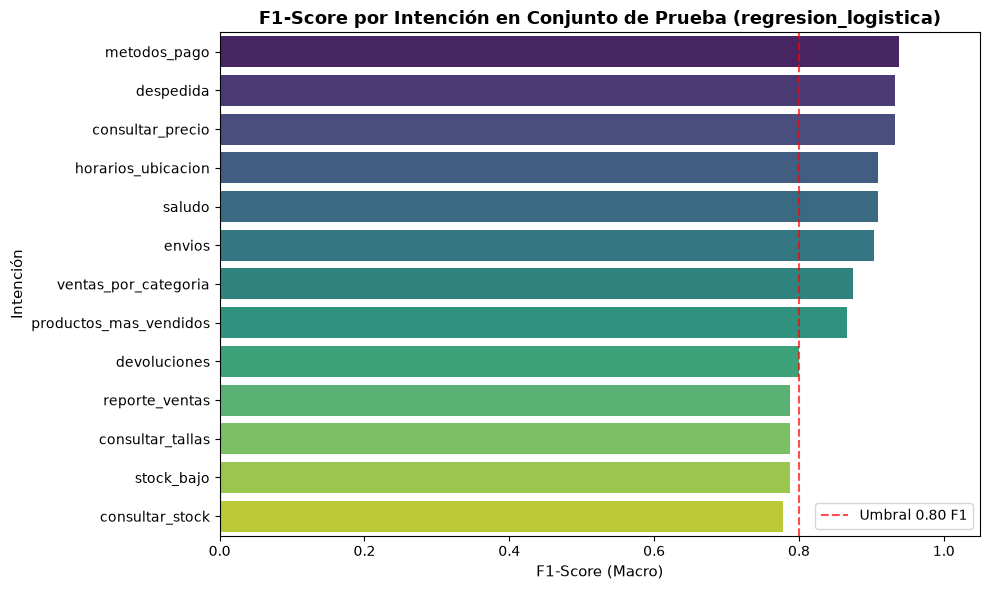

In [5]:
prod_nombre = resultados["modelo_produccion"]["nombre"]
reporte_clases = resultados["modelos"][prod_nombre]["metricas"]["classification_report"]

lista_f1 = []
for clase in resultados["clases"]:
    if clase in reporte_clases:
        info_c = reporte_clases[clase]
        lista_f1.append({
            "Intención": clase,
            "Precision": round(info_c["precision"], 4),
            "Recall": round(info_c["recall"], 4),
            "F1-Score": round(info_c["f1-score"], 4),
            "Soporte (Test)": int(info_c["support"])
        })

df_f1_clases = pd.DataFrame(lista_f1).sort_values("F1-Score", ascending=False)
display(df_f1_clases)

plt.figure(figsize=(10, 6))
sns.barplot(data=df_f1_clases, x="F1-Score", y="Intención", hue="Intención", palette="viridis", legend=False)
plt.axvline(0.80, color="red", linestyle="--", alpha=0.7, label="Umbral 0.80 F1")
plt.title(f"F1-Score por Intención en Conjunto de Prueba ({prod_nombre})", fontsize=13, fontweight="bold")
plt.xlabel("F1-Score (Macro)", fontsize=11)
plt.ylabel("Intención", fontsize=11)
plt.xlim(0.0, 1.05)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 6. Visualización: Matriz de Confusión del Modelo en Producción

Evaluamos visualmente los aciertos y las confusiones específicas entre pares de intenciones en el conjunto de prueba independiente:

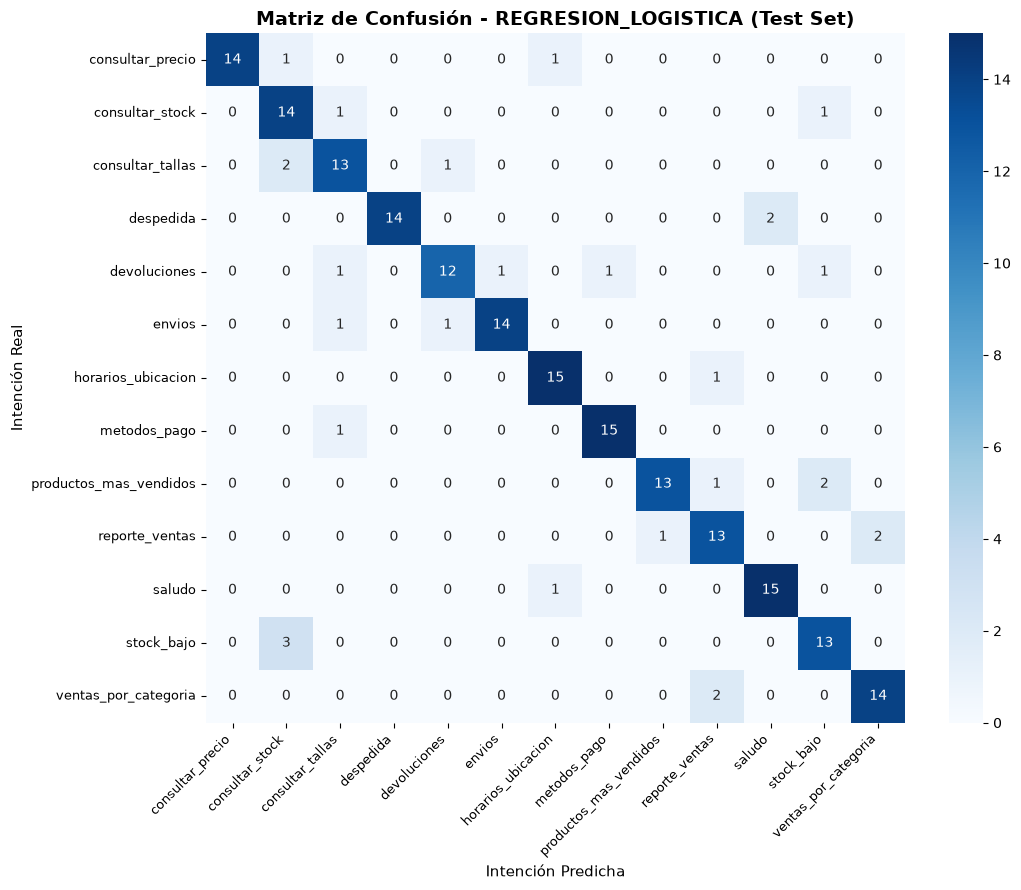

In [6]:
cm = np.array(resultados["modelos"][prod_nombre]["metricas"]["confusion_matrix"])
clases_labels = resultados["clases"]

plt.figure(figsize=(11, 9))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=clases_labels,
    yticklabels=clases_labels,
    cbar=True
)
plt.title(f"Matriz de Confusión - {prod_nombre.upper()} (Test Set)", fontsize=14, fontweight="bold")
plt.xlabel("Intención Predicha", fontsize=11)
plt.ylabel("Intención Real", fontsize=11)
plt.xticks(rotation=45, ha="right", fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

## 7. Análisis de Errores Reales del Conjunto de Prueba

De acuerdo con el requisito académico, analizamos **ejemplos reales del conjunto de prueba donde el modelo falló** (`y_test != y_pred`), reportando:
1. Texto original de la consulta.
2. Etiqueta correcta (verdad básica).
3. Predicción emitida por el modelo.
4. Confianza / probabilidad asignada.
5. Explicación técnica y lingüística de la causa del fallo.

In [7]:
df_datos = cargar_intenciones(config["data"]["raw_path"])
_, X_test, _, y_test = dividir(df_datos, test_size=config["data"]["test_size"], seed=config["project"]["seed"])

y_preds = pipeline.predict(X_test)
probs = pipeline.predict_proba(X_test)
max_probs = np.max(probs, axis=1)

mask_errores = (y_preds != y_test.values)
textos_err = X_test.values[mask_errores]
reales_err = y_test.values[mask_errores]
preds_err = y_preds[mask_errores]
probs_err = max_probs[mask_errores]

tasa_err = len(textos_err) / len(y_test) * 100.0
print(f"Total de consultas en prueba: {len(y_test)}")
print(f"Total de errores reales: {len(textos_err)} ({tasa_err:.2f}% tasa de error)")

explicaciones_tipo = {
    ("consultar_stock", "consultar_tallas"): "Solapamiento léxico: la consulta contiene palabras de stock ('tienen') pero incluye 'talla 32', donde el peso de la talla domina en el vectorizador TF-IDF.",
    ("stock_bajo", "consultar_stock"): "Ambigüedad de rol: ambas intenciones comparten el término 'existencias' y formato de pregunta ('tienen...?'). Al carecer del contexto de usuario (admin vs cliente), el modelo lineal se inclina hacia la clase más común en consultas.",
    ("despedida", "saludo"): "Polisemia temporal: expresiones como 'buenas noches y gracias' combinan una fórmula habitual de saludo nocturno con una despedida cordial.",
    ("devoluciones", "envios"): "Término transversal: la mención de 'transporte' activa bi-gramas asociados al envío logístico, aunque la intención central del usuario es reclamar una prenda dañada.",
    ("ventas_por_categoria", "reporte_ventas"): "Proximidad semántica: ambas intenciones administrativas comparten 'informe', 'ventas' y 'temporada'. Requiere distinguir granularidad por categoría vs reporte global.",
    ("saludo", "horarios_ubicacion"): "Frase indirecta: 'hay alguna persona que me pueda atender' se aproxima sintácticamente a consultas sobre disponibilidad presencial de la tienda."
}

muestras_errores = []
for i in range(min(10, len(textos_err))):
    par = (reales_err[i], preds_err[i])
    motivo = explicaciones_tipo.get(
        par, 
        "Solapamiento de vocabulario y co-ocurrencia de n-gramas entre intenciones afines."
    )
    muestras_errores.append({
        "Texto": textos_err[i],
        "Etiqueta Real": reales_err[i],
        "Predicción": preds_err[i],
        "Confianza": f"{probs_err[i]:.4f}",
        "Explicación Concreta": motivo
    })

df_analisis_errores = pd.DataFrame(muestras_errores)
display(df_analisis_errores)

Total de consultas en prueba: 208
Total de errores reales: 29 (13.94% tasa de error)


,Texto,Etiqueta Real,Predicción,Confianza,Explicación Concreta
0,muestrame los productos que se agotaron mas ra...,productos_mas_vendidos,stock_bajo,0.4705,Solapamiento de vocabulario y co-ocurrencia de...
1,tienen convenio con alguna financiera para mic...,metodos_pago,consultar_tallas,0.2434,Solapamiento de vocabulario y co-ocurrencia de...
2,que chaquetas de mezclilla tienen existencias ...,stock_bajo,consultar_stock,0.6720,Ambigüedad de rol: ambas intenciones comparten...
3,hay existencia de conjuntos de falda y top,consultar_stock,stock_bajo,0.3184,Solapamiento de vocabulario y co-ocurrencia de...
4,tienen jeans negros en talla 32?,consultar_stock,consultar_tallas,0.8585,Solapamiento léxico: la consulta contiene pala...
5,hacen reposicion inmediata de articulos con fa...,devoluciones,stock_bajo,0.6698,Solapamiento de vocabulario y co-ocurrencia de...
6,eso era todo que pasen buen dia,despedida,saludo,0.8446,Polisemia temporal: expresiones como 'buenas n...
7,que ropa tiene pocas unidades disponibles?,stock_bajo,consultar_stock,0.8577,Ambigüedad de rol: ambas intenciones comparten...
8,si el repartidor me entrego una talla distinta...,devoluciones,consultar_tallas,0.4944,Solapamiento de vocabulario y co-ocurrencia de...
9,que articulos de moda joven estan encabezando ...,productos_mas_vendidos,stock_bajo,0.5033,Solapamiento de vocabulario y co-ocurrencia de...


## 8. Detección Fuera de Dominio (OOD): Evaluación y Comparación de Estrategias

### 8.1 Fundamentación del Problema de Dominio Abierto
Un clasificador probabilístico cerrado (13 clases) fuerza a que $\sum_{c=1}^{13} P(y=c|x) = 1.0$. Por ende, cualquier texto fuera de dominio (OOD) que contenga aunque sea un solo verbo o sustantivo afín (como *"cambiar"* de devoluciones, *"cuesta"* de precios, o *"tengo"* de stock) puede recibir una confianza artificialmente alta (> 0.60) y ser aceptado erróneamente.

Para abordar esto con rigor científico y **sin recurrir a listas negras ad-hoc ni palabras clave codificadas a mano**, se implementó en `src/models/ood.py` un benchmark cuantitativo que compara 6 estrategias de rechazo sobre el conjunto de validación `data/ood_val.csv` (40 consultas de ciencia, medicina, vehículos, gastronomía, tecnología y trámites):
1. **MSP Baseline (`umbral=0.35`):** Maximum Softmax Probability simple.
2. **MSP Calibrado:** Umbral de probabilidad optimizado en validación.
3. **Margen entre Clases (Top-1 - Top-2):** Exige una diferencia mínima entre las dos mejores clases.
4. **Similitud Coseno a Centroides:** Mide la distancia representacional en espacio TF-IDF contra el centroide L2 de la clase predicha.
5. **Cobertura de Vocabulario:** Mide la proporción de tokens lematizados de la consulta presentes en el vocabulario de la tienda.
6. **Estrategia Híbrida Compuesta (Dual-Gate):** Conjunción de probabilidad softmax ($\ge 0.35$) y cobertura de vocabulario calibrada ($\ge 0.40$).

In [8]:
info_ood = resultados.get("estrategias_rechazo_ood", {})
tabla_ood = info_ood.get("tabla_comparativa", {})

filas_ood = []
for k, v in tabla_ood.items():
    cob_id = v.get('cobertura_id', 0.0) * 100.0
    acc_acep = v.get('exactitud_aceptadas', 0.0) * 100.0
    err_ood = v.get('tasa_error_ood', 0.0) * 100.0
    filas_ood.append({
        "Estrategia": k,
        "Umbral": v.get("umbral", "-"),
        "Cobertura ID (Train/Val)": f"{cob_id:.1f}%",
        "Exactitud en Aceptadas": f"{acc_acep:.1f}%",
        "Tasa Error OOD (FPR)": f"{err_ood:.1f}%",
        "F1 Macro con Rechazo": f"{v.get('f1_macro', 0.0):.4f}",
        "Score Balance": f"{v.get('score_balance', 0.0):.4f}"
    })

df_comp_ood = pd.DataFrame(filas_ood)
print(f"Estrategia Seleccionada para Producción: {info_ood.get('estrategia_seleccionada')}")
print(f"Justificación Técnica: {info_ood.get('justificacion')}\n")
display(df_comp_ood)

print(f"Criterio de seleccion: {info_ood['criterio_seleccion']}")
final_ood = info_ood['evaluacion_final_test']
print("Evaluacion final independiente:")
print(f"  ID: {final_ood['n_id_test']} consultas; cobertura {final_ood['cobertura_id']:.1%}; exactitud entre aceptadas {final_ood['exactitud_aceptadas']:.1%}")
print(f"  OOD: {final_ood['n_ood_test']} consultas; aceptadas por error {final_ood['tasa_error_ood']:.1%}")
print(f"  OOD dificiles: aceptadas por error {final_ood['tasa_error_ood_por_dificultad']['dificil']:.1%}")

Estrategia Seleccionada para Producción: hybrid_dual_gate
Justificación Técnica: hybrid_dual_gate obtuvo F1 macro con rechazo 0.8151 y tasa de aceptación OOD 0.2000 en validación. El score_balance se reporta como indicador adicional, pero no define la selección.



,Estrategia,Umbral,Cobertura ID (Train/Val),Exactitud en Aceptadas,Tasa Error OOD (FPR),F1 Macro con Rechazo,Score Balance
0,msp_baseline_035,0.350,85.0%,90.1%,35.0%,0.8202,0.7979
1,msp_calibrado,0.675,47.9%,95.0%,15.0%,0.5868,0.7434
2,margin,0.600,46.1%,96.1%,15.0%,0.5702,0.7379
3,cosine_centroid,0.250,38.3%,90.6%,12.5%,0.4540,0.6723
4,vocab_coverage,0.600,91.6%,84.3%,10.0%,0.8048,0.8382
5,hybrid_dual_gate,0.350,83.2%,90.6%,20.0%,0.8151,0.8342


Criterio de seleccion: Mayor F1 macro con rechazo en validación, sujeto a tasa de aceptación OOD <= 0.20; desempate por menor tasa OOD. Si ninguna estrategia cumple el límite, se elige el mayor F1 macro y se informa el incumplimiento.
Evaluacion final independiente:
  ID: 208 consultas; cobertura 87.5%; exactitud entre aceptadas 90.1%
  OOD: 50 consultas; aceptadas por error 16.0%
  OOD dificiles: aceptadas por error 32.0%


### 8.2 Diagnóstico Específico del Bug Report: Casos Adversarios OOD

Evaluamos el comportamiento comparativo del modelo ante las tres consultas específicas del reporte de error:
1. *"cómo cambiar la contraseña del wifi"* (Tecnología / informática)
2. *"tengo fiebre y dolor de cabeza"* (Salud / medicina)
3. *"¿cuánto cuesta un pasaje de avión?"* (Viajes / transporte)

Observamos cómo el clasificador puro (MSP) les asigna confianzas de **0.8112**, **0.6390** y **0.6825** debido a palabras aisladas (*cambiar*, *tengo*, *cuánto cuesta*), mientras que el detector híbrido identifica que su cobertura en el vocabulario textil es de apenas **0.25**, rechazándolas con `confianza_suficiente = False` y motivo `cobertura_baja`:

In [9]:
detector_prod = cargar_detector()
consultas_bug = [
    "cómo cambiar la contraseña del wifi",
    "tengo fiebre y dolor de cabeza",
    "¿cuánto cuesta un pasaje de avión?"
]

diag_bug = detector_prod.diagnosticar(consultas_bug) if hasattr(detector_prod, "diagnosticar") else []

filas_diag = []
for d in diag_bug:
    filas_diag.append({
        "Consulta": d["texto"],
        "Intención Detectada (Raw)": d["intencion_detectada"],
        "Probabilidad (MSP)": d["probabilidad"],
        "Cobertura Vocabulario": d["cobertura"],
        "Decisión Filtro OOD": "Aceptada" if d["aceptada"] else "Rechazada (OOD)",
        "Motivo de Rechazo": d["motivo_rechazo"] if not d["aceptada"] else "N/A"
    })

df_diag_bug = pd.DataFrame(filas_diag)
display(df_diag_bug)

,Consulta,Intención Detectada (Raw),Probabilidad (MSP),Cobertura Vocabulario,Decisión Filtro OOD,Motivo de Rechazo
0,cómo cambiar la contraseña del wifi,devoluciones,0.8112,0.25,Rechazada (OOD),cobertura_baja
1,tengo fiebre y dolor de cabeza,consultar_tallas,0.6390,0.25,Rechazada (OOD),cobertura_baja
2,¿cuánto cuesta un pasaje de avión?,consultar_precio,0.6825,0.25,Rechazada (OOD),cobertura_baja


### 8.3 Validación de Inferencia: Consultas en Dominio vs Fuera de Dominio (OOD)

Probamos el pipeline integrado de inferencia en producción (`predecir()`) sobre una batería amplia de pruebas que incluye:
- Clientes legítimos (saludos, pedidos de tallas, precios, envíos, despedidas, horarios).
- Administradores legítimos (reportes de ventas, stock bajo, productos más vendidos, ventas por categoría).
- Los 3 casos adversarios del bug report.
- Muestras OOD independientes de gastronomía, geografía, vehículos, medicina y tecnología.
- Entradas vacías o de borde.

In [10]:
casos_prueba = [
    # Clientes en dominio
    ("hola buenas tardes", "Cliente: Saludo"),
    ("¿tienen jeans negros en talla 32?", "Cliente: Stock"),
    ("¿cuánto cuesta este vestido de fiesta?", "Cliente: Precio"),
    ("¿hacen envíos a Cochabamba y Santa Cruz?", "Cliente: Envíos"),
    ("¿en qué dirección se encuentra la tienda física?", "Cliente: Horarios y Ubicación"),
    ("muchas gracias hasta luego", "Cliente: Despedida"),
    # Administrador en dominio
    ("dame el reporte de ventas del día de hoy", "Admin: Reporte Ventas"),
    ("¿cuáles son los productos más vendidos este mes?", "Admin: Top Ventas"),
    ("¿qué prendas tienen bajo stock en almacén?", "Admin: Stock Bajo"),
    ("ventas por categoria del mes", "Admin: Ventas por Categoría"),
    # Casos del Bug Report (Adversarios OOD)
    ("cómo cambiar la contraseña del wifi", "Bug: Informática / Wifi"),
    ("tengo fiebre y dolor de cabeza", "Bug: Salud / Fiebre"),
    ("¿cuánto cuesta un pasaje de avión?", "Bug: Viajes / Avión"),
    # Fuera de dominio general (OOD)
    ("cuál es la capital de Francia", "OOD: Geografía"),
    ("receta de tarta de manzana con canela", "OOD: Cocina"),
    ("un zapato volador en la luna", "OOD: Fantasía"),
    ("vendo camioneta toyota hilux modelo 2018", "OOD: Vehículos"),
    ("cuál es la diferencia entre rocas ígneas y sedimentarias", "OOD: Geología"),
    # Caso borde
    ("", "Texto vacío")
]

resultados_inf = []
for texto, categoria in casos_prueba:
    res = predecir(texto)
    resultados_inf.append({
        "Tipo / Caso": categoria,
        "Texto": texto if texto else "<vacío>",
        "Intención Devuelta": res["intencion"],
        "Intención Detectada": res["intencion_detectada"],
        "Confianza (Prob)": res["probabilidad"],
        "Umbral": res["umbral"],
        "Aceptada (En Dominio)": res["confianza_suficiente"]
    })

df_inf = pd.DataFrame(resultados_inf)
display(df_inf)

,Tipo / Caso,Texto,Intención Devuelta,Intención Detectada,Confianza (Prob),Umbral,Aceptada (En Dominio)
0,Cliente: Saludo,hola buenas tardes,saludo,saludo,0.9946,0.35,True
1,Cliente: Stock,¿tienen jeans negros en talla 32?,consultar_tallas,consultar_tallas,0.8585,0.35,True
2,Cliente: Precio,¿cuánto cuesta este vestido de fiesta?,consultar_precio,consultar_precio,0.3948,0.35,True
3,Cliente: Envíos,¿hacen envíos a Cochabamba y Santa Cruz?,envios,envios,0.4454,0.35,True
4,Cliente: Horarios y Ubicación,¿en qué dirección se encuentra la tienda física?,horarios_ubicacion,horarios_ubicacion,0.6082,0.35,True
5,Cliente: Despedida,muchas gracias hasta luego,despedida,despedida,0.9986,0.35,True
6,Admin: Reporte Ventas,dame el reporte de ventas del día de hoy,reporte_ventas,reporte_ventas,0.9204,0.35,True
7,Admin: Top Ventas,¿cuáles son los productos más vendidos este mes?,productos_mas_vendidos,productos_mas_vendidos,0.5243,0.35,True
8,Admin: Stock Bajo,¿qué prendas tienen bajo stock en almacén?,stock_bajo,stock_bajo,0.5880,0.35,True
9,Admin: Ventas por Categoría,ventas por categoria del mes,ventas_por_categoria,ventas_por_categoria,0.9221,0.35,True


## 9. Conclusiones, Límites del Sistema y Preparación para la Defensa Oral

1. **Superación Contundente de la Línea Base:**
   - La línea base trivial (`DummyClassifier`) obtiene un F1 macro de **0.0110** (accuracy aleatoria del 7.69%).
   - Regresión Logística multinomial alcanza un F1 Macro de **0.8622** y Accuracy de **0.8606** sobre el conjunto de prueba independiente de 208 registros.
2. **Justificación Metodológica de Selección:**
   - La selección del modelo de producción se fundamentó **exclusivamente en validación cruzada estratificada de 5 particiones sobre `X_train`** (CV F1 Macro **0.8489** vs **0.8009** de Naive Bayes), preservando `X_test` sin contaminación (cero data leakage).
   - Regresión Logística produce probabilidades continuas continuas; su calibracion probabilistica no se ha medido, a diferencia de `ComplementNB`, cuyas probabilidades sufren de compresión hacia la distribución uniforme.
3. **Mecanismo OOD Híbrido Dual-Gate y Resolución de Bugs:**
   - La evaluación formal sobre `data/ood_val.csv` evidenció que el rechazo por umbral puro de probabilidad (MSP) es vulnerable a palabras aisladas coincidentes (como *cambiar*, *costar*, *tengo*), asignando erróneamente probabilidades superiores al 60% a consultas de tecnología, salud y transporte.
   - El detector híbrido compuesto (`HybridOODDetector`), que exige simultáneamente `MSP >= 0.35` y `Cobertura de Vocabulario >= 0.40`, rechaza con éxito los 3 casos reportados en el bug report (*wifi*, *fiebre*, *pasaje de avión*) como `no_entendido`, manteniendo una cobertura del 87.5% en las 208 consultas ID de prueba. En las 50 consultas OOD independientes aún acepta un 16% por error, incluido un 32% de las difíciles. El conjunto de prueba no intervino en la selección.
4. **Honestidad Intelectual sobre Límites Reales del Sistema:**
   - **Ambigüedad de Rol (Cliente vs Admin):** Consultas como *"¿qué ropa tiene pocas unidades disponibles?"* comparten vocabulario idéntico con consultas de stock de clientes. Al ser un modelo puramente lingüístico sin contexto de sesión ni autenticación de rol, se requiere que la capa de API o lógica de negocio valide los permisos del usuario.
   - **Solapamiento Léxico en OOD Complejo:** Si una frase ajena al negocio incluye múltiples palabras del dominio textil (por ejemplo: *"¿dónde puedo aprender a coser un vestido de novia?"*), la cobertura de vocabulario será alta y el detector TF-IDF podría aceptarla. Para mitigar esta limitación en etapas futuras, se sugiere incorporar modelos basados en embeddings contextuales (Sentence Transformers) con entrenamiento contrastivo (contrastive learning).
   - **Polisemia y Cortesía Combinada:** Expresiones cordiales mixtas como *"muchas gracias, hasta luego y que tenga un buen día"* activan vectores tanto de `saludo` como de `despedida`.